# 03 · Model 1: Logistic Regression
**Owner:** Patil · **Family:** Linear/probabilistic · **Script:** `models/train_logreg.py`

**Why this model for PathSnap?** A linear, probabilistic baseline. Our features (relative distance, heading agreement, temporal closeness) are already strongly informative, so a linear boundary can go a long way. It also outputs calibrated probabilities, which the HMM needs as emission scores.

**Strengths:** very fast (about 1.5 s fit, about 3 ms per trip), interpretable coefficients, stable across folds, well-calibrated probabilities.

**Limitations:** can only learn a linear boundary in feature space, so it cannot capture interactions like 'small distance AND aligned heading' unless hand-crafted (e.g. `heading_cos_x_speed`). It needs feature scaling.

**Loss / objective:** binary cross-entropy (log loss) + L2 penalty (C=1), class-weighted ('balanced') for the ~14% positive rate, optimised with L-BFGS.

**Protocol (same for all 5 models, `models/common.py`):** 5-fold **GroupKFold by trip** on the 78 clean training trips (trips 54 and 33 excluded) → refit on all of them → evaluate on the 10 student_test trips (every GPS point). Primary metric: **observation-level Top-1 accuracy**. Only one fixed configuration per model: **no grid or random search** (organiser rule). Only the selected model is tuned, with Bayesian optimisation.

In [1]:
import os, sys
# run from the repository root regardless of where the notebook lives
_p = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(_p, "pathsnap")):
    _p = os.path.dirname(_p)
os.chdir(_p); sys.path.insert(0, _p)
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
print("repo root:", os.getcwd())
from models.train_logreg import est, cfg
from models.common import run_experiment
from pathsnap.features import FEATURE_COLUMNS
print("hyperparameters:", cfg)
est

repo root: C:\Users\shrey\OneDrive\Documents\ML Hackathon\PathSnap_7_H


hyperparameters: {'C': 1.0, 'penalty': 'l2', 'class_weight': 'balanced', 'max_iter': 2000, 'solver': 'lbfgs'}


,steps,"[('standardscaler', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


## Train, cross-validate and evaluate

In [2]:
row, model = run_experiment("logreg", "Linear/probabilistic", est, cfg)
pd.Series(row).drop("config_json")

[logreg] train rows=587,684 trips=78 | test rows=131,630


[logreg] CV macroF1=0.8812±0.0126 CV top1=0.8703 | test top1=0.8637 macroF1=0.8790 logloss=0.1667 cont=0.9479 | fit 1.5s, infer 3 ms/trip


model                                      logreg
family                       Linear/probabilistic
cv_macro_f1_mean                         0.881178
cv_macro_f1_std                          0.012568
cv_top1_mean                             0.870291
cv_top1_std                              0.026117
cv_logloss                               0.170735
train_top1                               0.871214
train_macro_f1                           0.882735
test_top1                                0.863674
test_macro_f1                            0.879047
test_precision                            0.69124
test_recall                              0.948655
test_logloss                             0.166713
test_cand_miss_rate                      0.002818
test_route_continuity_clf                0.947939
train_time_s                                 1.49
infer_ms_per_trip                            3.39
train_rows                                 587684
seed                                           42


In [3]:
log = json.load(open("results/model_runs/logreg.json"))
folds = pd.DataFrame(log["folds"]); display(folds.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
folds.plot(x="fold", y=["top1_accuracy", "macro_f1"], marker="o", ax=ax[0]); ax[0].set_title("Per-fold CV scores"); ax[0].set_ylim(0.75, 1)
bars = pd.Series({"train (fit data)": row["train_top1"], "CV (mean)": row["cv_top1_mean"], "student_test": row["test_top1"]})
bars.plot.bar(ax=ax[1], color=["C2", "C0", "C1"]); ax[1].set_ylim(0.75, 1); ax[1].set_title("Top-1: train vs CV vs test (over/underfitting)")
for i, v in enumerate(bars): ax[1].text(i, v + .005, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()

,macro_f1,precision,recall,logloss,top1_accuracy,candidate_miss_rate,fold,fit_s
0,0.8723,0.6874,0.9336,0.1914,0.8354,0.0074,0,0.99
1,0.8999,0.7426,0.9510,0.1472,0.8906,0.0176,1,0.95
2,0.8739,0.6834,0.9398,0.1672,0.8489,0.0165,2,1.32
3,0.8885,0.7128,0.9452,0.1487,0.8877,0.0028,3,1.24
4,0.8713,0.6843,0.9596,0.1990,0.8888,0.0009,4,1.09


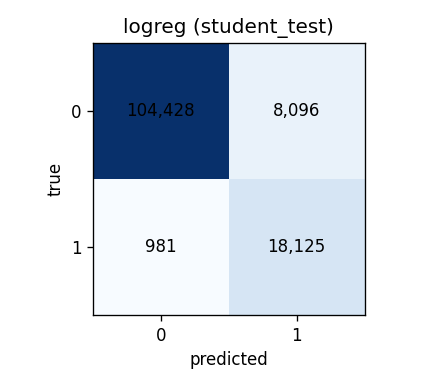

In [4]:
from IPython.display import Image
Image("results/plots/confusion_logreg.png")

## Coefficients (standardised features)

In [5]:
coef = pd.Series(model[-1].coef_[0], index=FEATURE_COLUMNS).sort_values()
plt.figure(figsize=(7, 5)); coef.plot.barh(color=np.where(coef > 0, "C2", "C3")); plt.title("LogReg coefficients (scaled features)")
plt.tight_layout(); plt.savefig("results/plots/logreg_coefficients.png"); plt.show()

In [6]:
r = row
gap = r["train_top1"] - r["cv_top1_mean"]
verdict = "overfitting (large train-CV gap)" if gap > 0.05 else ("mild overfitting" if gap > 0.02 else "no overfitting (train ≈ CV; if anything, high bias)")
print(f"""Student-test results  : Top-1 {r['test_top1']:.4f} | macro F1 {r['test_macro_f1']:.4f} | precision {r['test_precision']:.4f} | recall {r['test_recall']:.4f} | log loss {r['test_logloss']:.4f}
Route continuity (classifier-only argmax): {r['test_route_continuity_clf']:.4f}
CV Top-1 {r['cv_top1_mean']:.4f} ± {r['cv_top1_std']:.4f} | CV macro F1 {r['cv_macro_f1_mean']:.4f} ± {r['cv_macro_f1_std']:.4f}
Train Top-1 {r['train_top1']:.4f} -> train-CV gap {gap:+.4f}: {verdict}
Fit time {r['train_time_s']:.1f} s | inference {r['infer_ms_per_trip']:.0f} ms per trip""")

Student-test results  : Top-1 0.8637 | macro F1 0.8790 | precision 0.6912 | recall 0.9487 | log loss 0.1667
Route continuity (classifier-only argmax): 0.9479
CV Top-1 0.8703 ± 0.0261 | CV macro F1 0.8812 ± 0.0126
Train Top-1 0.8712 -> train-CV gap +0.0009: no overfitting (train ≈ CV; if anything, high bias)
Fit time 1.5 s | inference 3 ms per trip
